# PHQ-9 risk benchmark: Logistic Regression vs Random Forest vs XGBoost

**WARNING: the data is SYNTHETIC. Results are NOT clinically valid.**
Upload `dataset.csv` to the working directory (Colab: Files panel). If missing, it is generated inline.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])

In [2]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

SEED = 42
ITEM_COLS = [f"phq{i}" for i in range(1, 10)]
FEATURES = ITEM_COLS + ["age", "sex_male", "semester", "sleep_hours",
                        "weekly_study_hours", "works_part_time", "lives_with_family"]
CLASSES = ["low", "moderate", "high"]
NOISE_SD, THRESHOLDS = 3.0, (9.0, 15.0)

In [3]:
# Inline fallback generator (same as generate_dataset.py)
def generate(n: int = 2000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)

    age = np.clip(rng.normal(21, 2.5, n).round(), 17, 35).astype(int)
    sex_male = rng.binomial(1, 0.45, n)
    semester = np.clip(rng.integers(1, 11, n), 1, 10)
    sleep_hours = np.clip(rng.normal(6.6, 1.2, n), 3, 10).round(1)
    study_hours = np.clip(rng.normal(18, 8, n), 0, 50).round(1)
    works = rng.binomial(1, 0.35, n)
    family = rng.binomial(1, 0.7, n)

    # Latent depressive burden, mildly influenced by context.
    base = rng.beta(1.6, 3.2, n)
    base += 0.05 * (works) + 0.04 * (1 - family) + 0.03 * (6.5 - sleep_hours) / 2
    base = np.clip(base, 0, 1)

    items = np.zeros((n, 9), dtype=int)
    item_weight = np.array([1.0, 1.0, 1.1, 1.1, 0.9, 0.9, 0.9, 0.7, 0.35])
    for j in range(9):
        p = np.clip(base * item_weight[j] * 0.9 + rng.normal(0, 0.08, n), 0, 1)
        items[:, j] = rng.binomial(3, p)
    phq_sum = items.sum(axis=1)

    context = (
        0.8 * (7.0 - sleep_hours)
        + 0.06 * (study_hours - 18)
        + 1.0 * works
        + 1.2 * (1 - family)
        + 0.15 * (semester - 5)
    )
    severity = phq_sum + context + rng.normal(0, NOISE_SD, n)
    risk = np.where(severity < THRESHOLDS[0], "low",
                    np.where(severity < THRESHOLDS[1], "moderate", "high"))

    df = pd.DataFrame(items, columns=ITEM_COLS)
    df["age"] = age
    df["sex_male"] = sex_male
    df["semester"] = semester
    df["sleep_hours"] = sleep_hours
    df["weekly_study_hours"] = study_hours
    df["works_part_time"] = works
    df["lives_with_family"] = family
    df["risk_level"] = risk
    return df


In [4]:
if os.path.exists("dataset.csv"):
    df = pd.read_csv("dataset.csv"); print("loaded dataset.csv")
else:
    df = generate(2000, SEED); print("dataset.csv not found: generated inline")
print(df.shape); df["risk_level"].value_counts(normalize=True).round(3)

dataset.csv not found: generated inline
(2000, 17)


risk_level
low         0.533
moderate    0.308
high        0.158
Name: proportion, dtype: float64

In [5]:
X = df[FEATURES]
y = df["risk_level"].map({c: i for i, c in enumerate(CLASSES)}).values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.08, subsample=0.9,
                             colsample_bytree=0.9, objective="multi:softprob",
                             eval_metric="mlogloss", random_state=SEED, n_jobs=1),
}
high = CLASSES.index("high")
rows, cms = [], {}
for name, m in models.items():
    cvr = cross_validate(m, X_tr, y_tr, cv=cv, scoring={"f1": "f1_macro"})
    m.fit(X_tr, y_tr)
    proba = m.predict_proba(X_te); pred = proba.argmax(1)
    rows.append({"model": name,
        "cv_f1_macro": cvr["test_f1"].mean(),
        "accuracy": accuracy_score(y_te, pred),
        "f1_macro": f1_score(y_te, pred, average="macro"),
        "auc_macro_ovr": roc_auc_score(y_te, proba, multi_class="ovr", average="macro"),
        "recall_high": recall_score(y_te, pred, labels=[high], average="macro")})
    cms[name] = confusion_matrix(y_te, pred, labels=[0, 1, 2])
res = pd.DataFrame(rows).set_index("model").round(3)
res

,cv_f1_macro,accuracy,f1_macro,auc_macro_ovr,recall_high
model,,,,,
LogisticRegression,0.729,0.775,0.745,0.895,0.656
RandomForest,0.687,0.745,0.707,0.869,0.547
XGBoost,0.693,0.745,0.700,0.874,0.609


Winner (macro F1, tie-break AUC): LogisticRegression


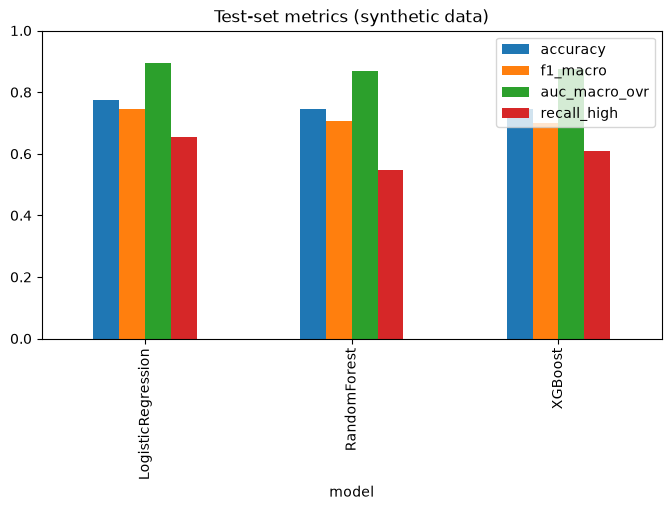

In [6]:
winner = res.sort_values(["f1_macro", "auc_macro_ovr"], ascending=False).index[0]
print("Winner (macro F1, tie-break AUC):", winner)
res[["accuracy", "f1_macro", "auc_macro_ovr", "recall_high"]].plot.bar(figsize=(8, 4), ylim=(0, 1))
plt.title("Test-set metrics (synthetic data)"); plt.show()

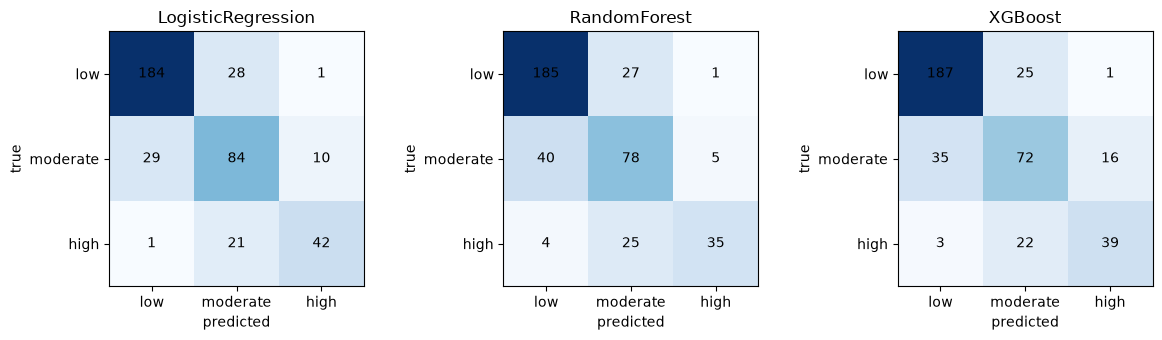

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, cm) in zip(axes, cms.items()):
    ax.imshow(cm, cmap="Blues"); ax.set_title(name)
    ax.set_xticks(range(3), CLASSES); ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, int(v), ha="center", va="center")
plt.tight_layout(); plt.show()